# 01A — Revisión de riesgos naturales | SiteWise
**Objetivo:** generar indicadores municipales intermedios de incendios históricos e inundación fluvial T10/T100 para los 8.132 municipios de la base LAU 2024. Ejecutar después del notebook 01 y antes del 02. No depende de resultados de notebooks posteriores; no entrena clustering ni modifica el dataset de producción.

## Contexto y metodología
- Civio / EGIF: incendios registrados de al menos 1 ha, 2002–2021 (20 años completos según la documentación de la fuente). La superficie se atribuye al municipio de origen, no necesariamente al territorio efectivamente quemado.
- JRC / Copernicus: rásteres T10 y T100 de profundidad modelizada; el indicador de superficie es una aproximación de píxeles centrales ponderada por latitud. NoData no equivale a ausencia de peligro. El modelo excluye cuencas pequeñas y no representa todos los mecanismos de inundación.
- MITECO: polígonos T100 de Península/Baleares y Canarias. Área de intersección municipal, sin contar solapamientos dos veces, en EPSG:6933. No intersección no equivale a ausencia de peligro.
- GISCO LAU 2024: universo municipal, código INE de cinco dígitos. Se conservan todos los municipios.

**Decisiones pendientes:** no imputar ceros por ausencia de registros, no fusionar directamente indicadores de distinta metodología y no construir aún un índice de riesgo. Las capas miden peligrosidad o histórico, no pérdidas ni riesgo de una parcela concreta.

Fuentes: [Civio](https://datos.civio.es/dataset/todos-los-incendios-forestales/), [JRC](https://doi.org/10.2905/JRC.WPE5YRR), [MITECO](https://www.miteco.gob.es/es/cartografia-y-sig/ide/descargas/agua/zi-lamina.html).

## 1. Configuración y rutas
Usar el kernel `.venv` del proyecto. Se aceptan las variantes de nombres de carpetas vistas en VS Code. Los nombres de los archivos se verifican y no se elige arbitrariamente si hay duplicados. El modo parcial es exclusivamente de prueba y guarda resultados en una carpeta separada.

In [1]:
from pathlib import Path
import os
import sys
from contextlib import ExitStack
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from shapely.ops import unary_union
import rasterio
from rasterio.features import geometry_mask, geometry_window
from rasterio.errors import WindowError
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "raw").is_dir()), None)
assert ROOT is not None, "Abre el notebook desde la raíz del proyecto o notebooks/"
RAW = ROOT / "data" / "raw"
riesgos_dirs = [RAW / x for x in ("riesgos_naturales", "riesgos_naturale") if (RAW / x).is_dir()]
assert len(riesgos_dirs) == 1, "Debe existir una única carpeta riesgos_naturales (o riesgos_naturale)"
RIESGOS = riesgos_dirs[0]
PARCIAL = os.getenv("SITEWISE_PRUEBA_PARCIAL", "0") == "1"
OUTPUT = ROOT / "data" / "interim" / ("riesgos_naturales_prueba" if PARCIAL else "riesgos_naturales")
OUTPUT.mkdir(parents=True, exist_ok=True)
ANIO_INICIO, ANIO_FIN = 2002, 2021
N_ANIOS = ANIO_FIN - ANIO_INICIO + 1
N_MUNICIPIOS = 8132
CRS_AREA = "EPSG:6933"
print("Proyecto:", ROOT, "| Python:", sys.executable)
print("GeoPandas:", gpd.__version__, "| Shapely:", shapely.__version__, "| Rasterio:", rasterio.__version__)
print("Modo parcial:", PARCIAL, "| Salida:", OUTPUT)

Proyecto: c:\PROYECTOS_ELE\Final_sidewise | Python: c:\PROYECTOS_ELE\Final_sidewise\.venv\Scripts\python.exe
GeoPandas: 1.2.0 | Shapely: 2.2.0 | Rasterio: 1.5.2
Modo parcial: False | Salida: c:\PROYECTOS_ELE\Final_sidewise\data\interim\riesgos_naturales


## 2. Verificación de entradas
Las capas T100 deben incluir `.shp`, `.shx`, `.dbf` y `.prj`. Los CSV intermedios de pruebas anteriores no son entradas: se recalculan desde las fuentes originales.

In [2]:
def buscar(base, patron, obligatorio=True):
    archivos = sorted(p for p in base.rglob("*") if p.is_file() and p.match(patron))
    if not archivos and not obligatorio:
        return None
    if len(archivos) != 1:
        raise ValueError(f"Esperaba un archivo {patron} en {base}; encontrados: {archivos}")
    return archivos[0]

rutas = {
    "municipios": buscar(RAW, "lau_2024_espana.geojson"),
    "incendios": buscar(RIESGOS, "fires-all.csv"),
    "jrc_t10": buscar(RIESGOS, "Europe_RP10_filled_depth.tif"),
    "jrc_t100": buscar(RIESGOS, "Europe_RP100_filled_depth.tif"),
    "miteco_pb": buscar(RIESGOS, "Q100_3Ciclo_PB*.shp", obligatorio=not PARCIAL),
    "miteco_canarias": buscar(RIESGOS, "Q100_2Ciclo_Canarias*.shp"),
}
for fuente, ruta in rutas.items():
    if ruta is None:
        print(f"{fuente}: AUSENTE (solo permitido en prueba parcial)")
        continue
    print(f"{fuente}: {ruta.relative_to(ROOT)} ({ruta.stat().st_size / 1e6:.1f} MB)")
    if ruta.suffix.lower() == ".shp":
        for ext in (".shx", ".dbf", ".prj"):
            assert ruta.with_suffix(ext).is_file(), f"Falta {ruta.with_suffix(ext)}"

municipios: data\raw\sitewise_v01\lau_2024_espana.geojson (10.6 MB)
incendios: data\raw\riesgos_naturales\incendios\fires-all.csv (32.8 MB)
jrc_t10: data\raw\riesgos_naturales\copernicus\Europe_RP10_filled_depth.tif (272.3 MB)
jrc_t100: data\raw\riesgos_naturales\copernicus\Europe_RP100_filled_depth.tif (323.1 MB)
miteco_pb: data\raw\riesgos_naturales\pb-100\Q100_3Ciclo_PB_20260727.shp (1833.6 MB)
miteco_canarias: data\raw\riesgos_naturales\canarias-100\Q100_2Ciclo_Canarias_20231218_ETRS89.shp (5.0 MB)


## 3. Base municipal
Se usa `AREA_KM2` para el indicador histórico de incendios y área geométrica proyectada para el cruce de polígonos. Las geometrías inválidas se reparan y se registran; no se eliminan municipios.

In [3]:
def solo_poligonos(geom):
    if geom is None or geom.is_empty:
        return shapely.Polygon()
    if geom.geom_type in ("Polygon", "MultiPolygon"):
        return geom
    if hasattr(geom, "geoms"):
        return unary_union([solo_poligonos(g) for g in geom.geoms])
    return shapely.Polygon()

def reparar_poligono(geom):
    if geom is None or geom.is_empty:
        return shapely.Polygon()
    return solo_poligonos(shapely.make_valid(geom) if not geom.is_valid else geom)

mun = gpd.read_file(rutas["municipios"])
assert mun.crs is not None, "La base municipal carece de CRS"
mun = mun.rename(columns={"LAU_NAME": "municipio", "AREA_KM2": "superficie_km2"})
mun["cod_ine"] = mun["GISCO_ID"].astype(str).str.extract(r"^ES_(\d{5})$", expand=False)
assert len(mun) == N_MUNICIPIOS and mun.cod_ine.is_unique and mun.cod_ine.notna().all()
mun["superficie_km2"] = pd.to_numeric(mun.superficie_km2, errors="raise")
assert (mun.superficie_km2 > 0).all()
mun = mun[["cod_ine", "municipio", "superficie_km2", "geometry"]].copy()
print("Geometrías municipales inválidas antes de reparar:", (~mun.is_valid).sum())
mun.geometry = mun.geometry.map(reparar_poligono)
assert mun.is_valid.all() and not mun.is_empty.any()
mun = mun.to_crs(4326).sort_values("cod_ine").reset_index(drop=True)
mun_area = mun.to_crs(CRS_AREA)
mun_area.geometry = mun_area.geometry.map(reparar_poligono)
assert mun_area.is_valid.all() and not mun_area.is_empty.any()
mun_area["area_geometrica_m2"] = mun_area.area
assert (mun_area.area_geometrica_m2 > 0).all()
base = pd.DataFrame(mun.drop(columns="geometry"))
print("Municipios:", len(base), "| Códigos únicos:", base.cod_ine.nunique())
display(base.head())

Geometrías municipales inválidas antes de reparar: 0
Municipios: 8132 | Códigos únicos: 8132


,cod_ine,municipio,superficie_km2
0,01001,Alegría-Dulantzi,19.945462
1,01002,Amurrio,96.270569
2,01003,Aramaio,73.126702
3,01004,Artziniega,27.306275
4,01006,Armiñón,12.967321


## 4. Incendios: reconciliar códigos y agregar
Equivalencias confirmadas para las fusiones Cerdedo-Cotobade y Oza-Cesuras (INE, BOE). Los registros no asignables se exportan para auditoría; no se reasignan por proximidad. No se asigna cero a municipios sin registro.

In [4]:
f = pd.read_csv(rutas["incendios"], usecols=["id", "fecha", "superficie", "idprovincia", "idmunicipio", "municipio", "lat", "lng", "latlng_explicit"])
assert f.id.notna().all() and f.id.is_unique, "Hay identificadores de incendio ausentes o duplicados"
f["anio"] = pd.to_datetime(f.fecha, errors="coerce").dt.year
print("Fechas no válidas:", int(f.anio.isna().sum()))
assert f.anio.notna().all(), "Revisar fechas antes de aplicar filtro temporal"
f = f[f.anio.between(ANIO_INICIO, ANIO_FIN)].copy()
f["superficie"] = pd.to_numeric(f.superficie, errors="raise")
assert f.superficie.notna().all() and (f.superficie >= 1).all(), "Revisar dominio de superficie (ha)"
prov = f.idprovincia.astype("Int64").astype("string").str.zfill(2)
mun_id = f.idmunicipio.astype("Int64").astype("string").str.zfill(3)
f["cod_ine_original"] = prov + mun_id
mapa = {"36011": "36902", "36012": "36902", "15026": "15902", "15063": "15902"}
assert set(mapa.values()) <= set(base.cod_ine)
f["cod_ine"] = f.cod_ine_original.replace(mapa)
f["estado_asignacion"] = np.select(
    [f.cod_ine_original.isin(mapa), f.cod_ine.isin(base.cod_ine)],
    ["fusion_documentada", "codigo_directo"], default="pendiente")
pendientes = f[f.estado_asignacion.eq("pendiente")].copy()
fusiones = f[f.estado_asignacion.eq("fusion_documentada")].copy()
validos = f[f.estado_asignacion.ne("pendiente")]
agregado = validos.groupby("cod_ine").agg(
    incendios_ge1ha_registrados_2002_2021_n=("id", "size"),
    superficie_incendios_origen_2002_2021_ha=("superficie", "sum"),
).reset_index()
incendios = base.merge(agregado, on="cod_ine", how="left", validate="one_to_one")
incendios["incendios_ge1ha_100km2_anio"] = incendios.incendios_ge1ha_registrados_2002_2021_n * 100 / (N_ANIOS * incendios.superficie_km2)
incendios["estado_incendios"] = np.where(incendios.incendios_ge1ha_registrados_2002_2021_n.notna(), "con_registros", "sin_registros_asignados")
assert int(incendios.incendios_ge1ha_registrados_2002_2021_n.sum()) + len(pendientes) == len(f)
print(f.estado_asignacion.value_counts().to_string())
print(incendios.estado_incendios.value_counts().to_string())
display(f.groupby("anio").size().rename("incendios").to_frame())

Fechas no válidas: 0
estado_asignacion
codigo_directo        94366
fusion_documentada      272
pendiente               100
estado_incendios
con_registros              5984
sin_registros_asignados    2148


,incendios
anio,
2002,7816
2003,6622
2004,7643
2005,9011
2006,5590
2007,3408
2008,4352
2009,5772
2010,3907


## 5. Inundaciones JRC (T10 y T100)
Lectura por ventanas: no se cargan los rásteres completos en RAM. El porcentaje es la fracción aproximada del municipio con píxeles de profundidad positiva respecto a todos sus píxeles centrales; la fracción con datos válidos se mantiene separada. Si no hay píxeles válidos o la extensión no cubre el municipio, el porcentaje queda ausente. No se rellena NoData con cero. Profundidad media exclusivamente sobre píxeles positivos.

In [5]:
def cruce_raster(municipios, ruta, periodo):
    rows = []
    with rasterio.Env(GDAL_CACHEMAX=128 * 1024 * 1024), rasterio.open(ruta) as r:
        assert r.crs is not None and r.crs.to_epsg() == 4326, "Se esperaba CRS EPSG:4326"
        assert r.transform.b == 0 and r.transform.d == 0, "Ráster rotado no soportado"
        huella = box(*r.bounds)
        print(f"T{periodo}: {r.width} x {r.height}, NoData={r.nodata}", flush=True)
        for i, (cod, geom) in enumerate(zip(municipios.cod_ine, municipios.geometry), start=1):
            k = f"jrc_t{periodo}"
            rec = {"cod_ine": cod, f"{k}_pixeles_municipio": 0,
                   f"{k}_pixeles_validos": 0, f"{k}_pixeles_positivos": 0,
                   f"{k}_pixeles_cero": 0, f"{k}_pixeles_negativos": 0,
                   f"{k}_fraccion_valida_pct": np.nan,
                   f"{k}_area_positiva_pct": np.nan, f"{k}_profundidad_positiva_media_m": np.nan,
                   f"{k}_estado": "fuera_extension_raster"}
            try:
                w = geometry_window(r, [geom])
            except WindowError:
                rows.append(rec)
                continue
            t = r.window_transform(w)
            a = r.read(1, window=w, masked=True)
            dentro = geometry_mask([geom], out_shape=a.shape, transform=t, invert=True)
            n = int(dentro.sum())
            rec[f"{k}_pixeles_municipio"] = n
            if not n:
                rec[f"{k}_estado"] = "sin_pixeles_centrales"
                rows.append(rec)
                continue
            vals = np.asarray(a.data)
            disponible = dentro & ~np.ma.getmaskarray(a) & np.isfinite(vals)
            negativo = disponible & (vals < 0)
            valido = disponible & (vals >= 0)
            positivo = valido & (vals > 0)
            cero = valido & (vals == 0)
            pesos = np.cos(np.deg2rad(t.f + (np.arange(a.shape[0]) + .5) * t.e))[:, None]
            denom = float(np.sum(dentro * pesos))
            rec.update({f"{k}_pixeles_validos": int(valido.sum()), f"{k}_pixeles_positivos": int(positivo.sum()),
                        f"{k}_pixeles_cero": int(cero.sum()), f"{k}_pixeles_negativos": int(negativo.sum()),
                        f"{k}_fraccion_valida_pct": 100 * np.sum(valido * pesos) / denom})
            if positivo.any():
                rec[f"{k}_profundidad_positiva_media_m"] = float(np.average(vals[positivo], weights=np.broadcast_to(pesos, a.shape)[positivo]))
                rec[f"{k}_estado"] = "con_profundidad_positiva"
            elif valido.any():
                rec[f"{k}_estado"] = "sin_positivos_con_datos_parciales"
            else:
                rec[f"{k}_estado"] = "sin_pixeles_validos"
            if not huella.covers(geom):
                rec[f"{k}_estado"] += "__extension_parcial"
            elif positivo.any() or (valido.sum() == n):
                rec[f"{k}_area_positiva_pct"] = 100 * np.sum(positivo * pesos) / denom
                if not positivo.any():
                    rec[f"{k}_estado"] = "cero_modelizado_en_todos_los_pixeles"
            rows.append(rec)
            if i % 2000 == 0:
                print(f"  {i}/{len(municipios)}", flush=True)
    return pd.DataFrame(rows)

jrc10 = cruce_raster(mun, rutas["jrc_t10"], 10)
jrc100 = cruce_raster(mun, rutas["jrc_t100"], 100)
for tabla, periodo in [(jrc10, 10), (jrc100, 100)]:
    print(f"T{periodo}:", tabla[f"jrc_t{periodo}_estado"].value_counts().to_dict())

T10: 110162 x 51992, NoData=-9999.0
  2000/8132
  4000/8132
  6000/8132
  8000/8132
T100: 110162 x 51992, NoData=-9999.0
  2000/8132
  4000/8132
  6000/8132
  8000/8132
T10: {'con_profundidad_positiva': 4975, 'sin_pixeles_validos': 3151, 'sin_pixeles_validos__extension_parcial': 5, 'fuera_extension_raster': 1}
T100: {'con_profundidad_positiva': 5004, 'sin_pixeles_validos': 3122, 'sin_pixeles_validos__extension_parcial': 5, 'fuera_extension_raster': 1}


## 6. MITECO T100: intersección de polígonos
Reparación de polígonos inválidos y proyección a EPSG:6933. Se usa índice espacial por municipio y unión de las intersecciones para no duplicar superficies. Los municipios sin intersección quedan sin dato de área; no se presupone que todos sus cauces hayan sido estudiados. Se guardan las estadísticas de reparación y los polígonos descartados en el informe de calidad.

In [6]:
from time import perf_counter

def cruce_vector(municipios_area, ruta, etiqueta, provincias=None):

    inicio = perf_counter()

    subset = (
        municipios_area
        if provincias is None
        else municipios_area[
            municipios_area.cod_ine.str[:2].isin(provincias)
        ]
    )

    k = f"miteco_t100_{etiqueta}"

    if ruta is None:
        return pd.DataFrame({
            "cod_ine": subset.cod_ine,
            f"{k}_area_m2": np.nan,
            f"{k}_area_pct": np.nan,
            f"{k}_estado": "fuente_ausente_prueba"
        }), {"fuente": etiqueta, "ausente": True}

    print(f"\n--- PROCESANDO {etiqueta.upper()} ---", flush=True)

    print("1/6 Cargando archivo SHP...", flush=True)
    capa = gpd.read_file(ruta, columns=[])

    assert capa.crs is not None, f"CRS ausente: {ruta}"

    stats = {
        "fuente": etiqueta,
        "archivo": ruta.name,
        "geometrias_originales": len(capa),
        "invalidas_originales": int((~capa.is_valid).sum()),
        "crs": str(capa.crs)
    }

    print(f"Geometrías cargadas: {len(capa)}", flush=True)

    def reparar_necesarias(capa):
        capa = capa[["geometry"]].copy()

        invalidas = capa.geometry.notna() & (
            ~capa.is_valid
            | ~capa.geom_type.isin(["Polygon", "MultiPolygon"])
        )

        indices = capa.index[invalidas]

        print(
            f"Geometrías que requieren reparación: "
            f"{len(indices)} de {len(capa)}",
            flush=True
        )

        for i, idx in enumerate(indices, 1):

            print(
                f"Reparando {i}/{len(indices)} "
                f"- índice {idx}",
                flush=True
            )

            capa.at[idx, "geometry"] = reparar_poligono(
                capa.at[idx, "geometry"]
            )

        return capa

    print("2/6 Reparando geometrías...", flush=True)
    capa = reparar_necesarias(capa)

    print("3/6 Transformando coordenadas...", flush=True)
    capa = capa.to_crs(CRS_AREA)
    capa = reparar_necesarias(capa)

    stats["descartadas_sin_poligono"] = int(
        capa.is_empty.sum()
    )

    capa = capa[
        capa.geometry.notna() & ~capa.is_empty
    ].reset_index(drop=True)

    assert len(capa) and capa.is_valid.all()

    print("4/6 Construyendo índice espacial...", flush=True)

    # Separar multipolígonos para mejorar las búsquedas
    capa = capa.explode(
        index_parts=False,
        ignore_index=True
    )

    indice = capa.sindex

    print("5/6 Cruzando municipios...", flush=True)

    rows = []
    total = len(subset)

    for i, (cod, geom, area) in enumerate(
        zip(
            subset.cod_ine,
            subset.geometry,
            subset.area_geometrica_m2
        ), 1
    ):

        candidatos = indice.query(
            geom,
            predicate="intersects"
        )

        rec = {
            "cod_ine": cod,
            f"{k}_area_m2": np.nan,
            f"{k}_area_pct": np.nan,
            f"{k}_estado": "sin_interseccion_cartografiada"
        }

        if len(candidatos):

            piezas = shapely.intersection(
                capa.geometry.iloc[candidatos].array,
                geom
            )

            piezas = [
                solo_poligonos(p)
                for p in piezas
                if not p.is_empty
            ]

            area_inter = (
                float(unary_union(piezas).area)
                if piezas else 0.0
            )

            if area_inter > 0:

                pct = 100 * area_inter / area

                assert pct <= 100.0001, (
                    f"Área superior al municipio {cod}: {pct}"
                )

                rec.update({
                    f"{k}_area_m2": area_inter,
                    f"{k}_area_pct": min(pct, 100),
                    f"{k}_estado":
                        "con_interseccion_cartografiada"
                })

        rows.append(rec)

        if i == 1 or i % 250 == 0 or i == total:

            print(
                f"{etiqueta}: {i}/{total} "
                f"({100*i/total:.1f}%)",
                flush=True
            )

    print("6/6 Generando resultados...", flush=True)

    tabla = pd.DataFrame(rows)

    stats["municipios_con_interseccion"] = int(
        tabla[f"{k}_area_m2"].notna().sum()
    )

    stats["tiempo_segundos"] = round(
        perf_counter() - inicio, 2
    )

    print(stats, flush=True)

    return tabla, stats


# Península y Baleares
provincias_pb = sorted(
    set(mun.cod_ine.str[:2]) - {"35", "38"}
)

pb, stats_pb = cruce_vector(
    mun_area,
    rutas["miteco_pb"],
    "pb",
    provincias_pb
)

# Canarias
canarias, stats_can = cruce_vector(
    mun_area,
    rutas["miteco_canarias"],
    "canarias",
    ["35", "38"]
)
 


--- PROCESANDO PB ---
1/6 Cargando archivo SHP...


c:\PROYECTOS_ELE\Final_sidewise\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: c:\PROYECTOS_ELE\Final_sidewise\data\raw\riesgos_naturales\pb-100\Q100_3Ciclo_PB_20260727.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


Geometrías cargadas: 6222
2/6 Reparando geometrías...
Geometrías que requieren reparación: 513 de 6222
Reparando 1/513 - índice 40
Reparando 2/513 - índice 49
Reparando 3/513 - índice 169
Reparando 4/513 - índice 204
Reparando 5/513 - índice 207
Reparando 6/513 - índice 316
Reparando 7/513 - índice 325
Reparando 8/513 - índice 331
Reparando 9/513 - índice 332
Reparando 10/513 - índice 333
Reparando 11/513 - índice 335
Reparando 12/513 - índice 336
Reparando 13/513 - índice 338
Reparando 14/513 - índice 339
Reparando 15/513 - índice 342
Reparando 16/513 - índice 343
Reparando 17/513 - índice 344
Reparando 18/513 - índice 345
Reparando 19/513 - índice 349
Reparando 20/513 - índice 351
Reparando 21/513 - índice 352
Reparando 22/513 - índice 353
Reparando 23/513 - índice 354
Reparando 24/513 - índice 355
Reparando 25/513 - índice 356
Reparando 26/513 - índice 385
Reparando 27/513 - índice 391
Reparando 28/513 - índice 393
Reparando 29/513 - índice 396
Reparando 30/513 - índice 402
Reparand

## 7. Consolidar y validar
Se conserva la procedencia de cada resultado. La columna MITECO T100 unificada combina exclusivamente las dos capas territoriales del mismo organismo; JRC queda en columnas separadas. No se mezclan numéricamente MITECO y JRC ni se imputa por vecinos. La disponibilidad positiva es un indicador de presencia de evidencia, no una medida de cobertura cartográfica completa.

In [7]:
resultado = incendios.copy()
for tabla in (jrc10, jrc100, pb, canarias):
    resultado = resultado.merge(tabla, on="cod_ine", how="left", validate="one_to_one")
is_can = resultado.cod_ine.str[:2].isin(["35", "38"])
for campo in ("area_m2", "area_pct", "estado"):
    resultado[f"miteco_t100_{campo}"] = resultado[f"miteco_t100_pb_{campo}"].where(~is_can, resultado[f"miteco_t100_canarias_{campo}"])
resultado["miteco_t100_fuente"] = np.where(is_can, "MITECO_Canarias", "MITECO_PB")
resultado["evidencia_inundacion_t100"] = resultado.jrc_t100_pixeles_positivos.gt(0) | resultado.miteco_t100_area_m2.notna()
resultado["evidencia_incendios"] = resultado.incendios_ge1ha_registrados_2002_2021_n.notna()
resultado["evidencia_ambos"] = resultado.evidencia_inundacion_t100 & resultado.evidencia_incendios
assert len(resultado) == N_MUNICIPIOS and resultado.cod_ine.is_unique
assert set(resultado.cod_ine) == set(base.cod_ine) and resultado.cod_ine.str.fullmatch(r"\d{5}").all()
for c in [x for x in resultado.columns if x.endswith("_pct")]:
    assert resultado[c].dropna().between(0, 100.0001).all(), f"Fuera de rango: {c}"
assert resultado.loc[resultado.estado_incendios.eq("sin_registros_asignados"), "incendios_ge1ha_registrados_2002_2021_n"].isna().all()
for p in (10, 100):
    assert resultado.loc[resultado[f"jrc_t{p}_pixeles_validos"].eq(0), f"jrc_t{p}_area_positiva_pct"].isna().all()
assert resultado.loc[resultado.miteco_t100_estado.ne("con_interseccion_cartografiada"), "miteco_t100_area_pct"].isna().all()
print("Validaciones de integridad superadas")

Validaciones de integridad superadas


## 8. Resultados y disponibilidad municipal
Se informa por provincia para detectar diferencias territoriales. Los valores positivos de fuentes diferentes no son estimaciones equivalentes del riesgo. El porcentaje de municipios con evidencia no implica que el resto carezca de peligro.

,municipios_con_evidencia,pct
indicador,,
incendios,5984,73.59
JRC T10,4975,61.18
JRC T100,5004,61.53
MITECO T100,4086,50.25
Inundacion T100 (alguna fuente),5834,71.74
Ambos fenomenos,4595,56.51


,municipios,incendios,JRC T10,JRC T100,MITECO T100,Inundacion T100 (alguna fuente),Ambos fenomenos
provincia,,,,,,,
07,67,47,0,0,9,9,6
35,34,18,0,0,13,13,6
38,54,37,0,0,14,14,12
51,1,1,1,1,1,1,1
52,1,0,1,1,1,1,0


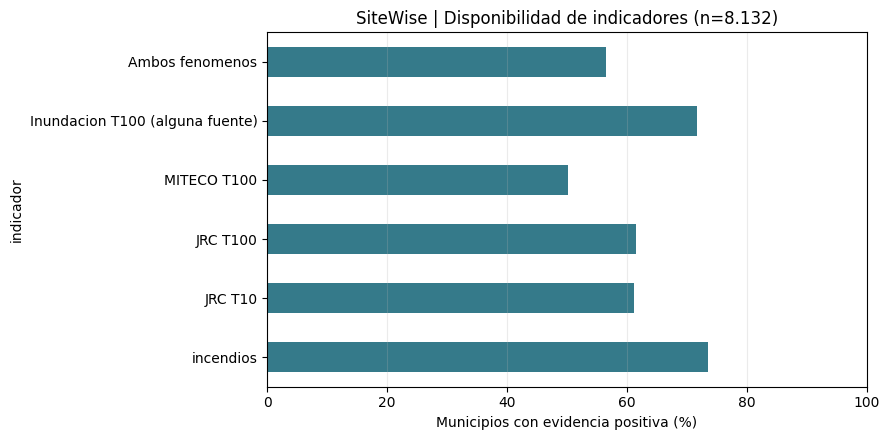

In [8]:
flags = pd.DataFrame({"cod_ine": resultado.cod_ine,
    "incendios": resultado.evidencia_incendios,
    "JRC T10": resultado.jrc_t10_pixeles_positivos.gt(0),
    "JRC T100": resultado.jrc_t100_pixeles_positivos.gt(0),
    "MITECO T100": resultado.miteco_t100_area_m2.notna(),
    "Inundacion T100 (alguna fuente)": resultado.evidencia_inundacion_t100,
    "Ambos fenomenos": resultado.evidencia_ambos})
cols = list(flags.columns[1:])
resumen = pd.DataFrame({"municipios_con_evidencia": flags[cols].sum(), "pct": flags[cols].mean() * 100})
resumen.index.name = "indicador"
display(resumen.round(2))
por_prov = flags.assign(provincia=flags.cod_ine.str[:2]).groupby("provincia")[cols].sum()
por_prov.insert(0, "municipios", flags.cod_ine.str[:2].value_counts())
display(por_prov.loc[["07", "35", "38", "51", "52"]])
ax = resumen.pct.plot.barh(figsize=(9, 4.5), xlim=(0, 100), color="#357a8a")
ax.set_xlabel("Municipios con evidencia positiva (%)")
ax.set_title("SiteWise | Disponibilidad de indicadores (n=8.132)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

## 9. Exportación reproducible
Los archivos son **intermedios**. En modo parcial se guardan exclusivamente en `data/interim/riesgos_naturales_prueba/`; no deben integrarse en producción. Los indicadores finales y el contrato con el notebook 03 se decidirán después de revisar la cobertura y la comparabilidad. Mantener `cod_ine` como texto al leer CSV.

In [9]:
resultado.to_csv(OUTPUT / "indicadores_riesgos_naturales_v01.csv", index=False)
incendios.to_csv(OUTPUT / "incendios_civio_reconciliado_v01.csv", index=False)
fusiones.to_csv(OUTPUT / "incendios_fusiones_reconciliadas.csv", index=False)
pendientes.to_csv(OUTPUT / "incendios_pendientes_reconciliacion.csv", index=False)
resumen.to_csv(OUTPUT / "cobertura_riesgos_v01.csv")
por_prov.to_csv(OUTPUT / "cobertura_riesgos_por_provincia_v01.csv")
pd.DataFrame([stats_pb, stats_can]).to_csv(OUTPUT / "calidad_geometrias_miteco_v01.csv", index=False)
pd.DataFrame([{"fuente": k, "archivo": str(v.relative_to(ROOT)) if v else None, "bytes": v.stat().st_size if v else None,
               "modo_parcial": PARCIAL} for k, v in rutas.items()]).to_csv(OUTPUT / "inventario_fuentes_v01.csv", index=False)
print("Archivos generados:")
for p in sorted(OUTPUT.glob("*.csv")):
    print("-", p.name)
print("Modo parcial:", PARCIAL)

Archivos generados:
- calidad_geometrias_miteco_v01.csv
- cobertura_riesgos_por_provincia_v01.csv
- cobertura_riesgos_v01.csv
- incendios_civio_reconciliado_v01.csv
- incendios_fusiones_reconciliadas.csv
- incendios_pendientes_reconciliacion.csv
- indicadores_riesgos_naturales_v01.csv
- inventario_fuentes_v01.csv
Modo parcial: False
